# NB 01 · Collecte et nettoyage : le pipeline d'ingestion

**Rôle joué :** ingénieur de la chaîne de traitement du renseignement. Les sources brutes arrivent sales : mentions légales, doublons, encodages cassés, signatures qui trahissent la source. Ta mission est de produire des **corpus propres, au même format**, que tous les notebooks suivants consommeront.

**Produits livrés dans `outputs/` :**

| Fichier | Contenu | Utilisé par |
|---|---|---|
| `corpus_golfe.parquet` | presse Iran / États-Unis 2025-2026 | NB 02 (NER), NB 04 (graphe) |
| `corpus_ukraine.parquet` | Telegram 2022-2023, 12 chaînes, 5 camps | NB 03 (alerte), NB 05, NB 06 |
| `verite_terrain_hormuz.parquet` | mesures physiques du détroit | NB 03, NB 06 |
| `entrainement_infowar.parquet` | fiable / désinformation / propagande | NB 05 |

> **Pourquoi Parquet et pas CSV ?** C'est un format colonne, compressé et typé : les dates restent des dates. Il se recharge environ 10 fois plus vite. C'est le standard des data lakes professionnels.

**Le schéma commun de chaque document :** `doc_id · date · source · camp · titre · texte · langue · url · theatre`

In [1]:
import sys
from pathlib import Path

# On retrouve la racine du projet (le dossier qui contient data_lake/) pour importer src/
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_lake").is_dir())
sys.path.insert(0, str(RACINE / "src"))

import re

import matplotlib.pyplot as plt
import pandas as pd

from spirit_digger.cleaning import detecter_langue_latine, empreinte, nettoyer_texte, retirer_signatures
from spirit_digger.config import CAMPS_TELEGRAM, OUTPUTS
from spirit_digger.loaders import charger
from spirit_digger.style import ACCENT, ALERTE, OK, VEILLE, bandeau, theme_ops

theme_ops()
pd.set_option("display.max_colwidth", 140)
bandeau("NB 01 · Pipeline d'ingestion", "Sources brutes → corpus propres, dédoublonnés, au format commun.")

COLONNES = ["doc_id", "date", "source", "camp", "titre", "texte", "langue", "url", "theatre"]
journal = []  # trace de chaque étape : ce qu'on a gardé, ce qu'on a jeté


def tracer(theatre, etape, n):
    journal.append({"corpus": theatre, "étape": etape, "documents": n})
    print(f"[{theatre}] {etape:<32} → {n:>8,} documents")

## 1. Théâtre GOLFE : presse Iran / États-Unis

Étapes : normaliser les champs, séparer le **média** du **canal de collecte** (`Bing-Al Jazeera` donne le média Al Jazeera, collecté via Bing), détecter la langue, dédoublonner, puis écarter les textes trop courts pour être exploitables.

Le nettoyage retire aussi les **résidus de pages web** (« To play this video you need to enable JavaScript… », boutons de partage). Sans ça, l'extraction d'entités du NB 02 trouverait « HTML5 » et « JavaScript » parmi les acteurs du conflit.

In [2]:
iran = charger("iran_us_news")
tracer("GOLFE", "chargement brut", len(iran))

golfe = pd.DataFrame({
    "date": pd.to_datetime(iran["date"], errors="coerce"),
    "source": iran["_source"].str.replace(r"^(Bing|RSS)-", "", regex=True).str.strip(),
    "camp": iran["_source"].str.extract(r"^(Bing|RSS)-", expand=False).fillna("Direct"),
    "titre": iran["title"].map(nettoyer_texte),
    "texte": iran["content"].map(nettoyer_texte),
    "url": iran["link"],
    "theatre": "GOLFE",
})
golfe["requete"] = iran["_keyword"]  # mot-clé ayant servi à la collecte : utile pour auditer les biais
golfe["langue"] = golfe["texte"].map(detecter_langue_latine)

# « dw » et « DW » sont le même média : on garde l'orthographe la plus fréquente
orthographe = golfe["source"].groupby(golfe["source"].str.lower()).agg(lambda s: s.value_counts().index[0])
golfe["source"] = golfe["source"].str.lower().map(orthographe)

golfe = golfe.drop_duplicates("url")
tracer("GOLFE", "doublons d'URL retirés", len(golfe))

golfe["empreinte"] = (golfe["titre"] + " " + golfe["texte"]).map(empreinte)
golfe = golfe.drop_duplicates("empreinte")
tracer("GOLFE", "doublons de contenu retirés", len(golfe))

golfe = golfe[golfe["texte"].str.len() >= 200]
tracer("GOLFE", "textes < 200 caractères écartés", len(golfe))

[GOLFE] chargement brut                  →    2,286 documents


[GOLFE] doublons d'URL retirés           →    2,286 documents


[GOLFE] doublons de contenu retirés      →    2,251 documents
[GOLFE] textes < 200 caractères écartés  →    2,231 documents


**Note :** dans le corpus GOLFE, la colonne `camp` contient le **canal de collecte** (Bing, RSS, Direct). Dans le corpus UKRAINE, elle contient le **camp politique**. C'est le même rôle : savoir d'où vient l'information.

In [3]:
golfe = golfe.sort_values("date", na_position="last").reset_index(drop=True)
golfe["doc_id"] = [f"G-{i:05d}" for i in range(len(golfe))]

golfe[COLONNES + ["requete"]].to_parquet(OUTPUTS / "corpus_golfe.parquet", index=False)
display(golfe["langue"].value_counts().rename("articles par langue"))
display(golfe["source"].value_counts().head(8).rename("articles"))
golfe[["doc_id", "date", "source", "titre"]].dropna(subset=["date"]).tail(5)

langue
en    2196
id      35
Name: articles par langue, dtype: int64

source
BBC                   1083
DW                     156
Crypto Briefing         71
The Guardian            64
Tempo                   54
The Independent         46
Al Jazeera English      37
BBC Middle East         36
Name: articles, dtype: int64

,doc_id,date,source,titre
724,G-00724,2026-06-14 12:35:06,The Independent,Ukraine-Russia war latest: Kyiv bombs oil refinery and chemical plant used to make explosives in overnight strikes
725,G-00725,2026-06-14 12:51:40,The Independent,Why four states have banned billboards
726,G-00726,2026-06-14 14:54:52,Hindustan Times,Revealed: How Ali Khamenei's one move in 1984 helped Iran ward off Israel & USA in 2025 & 2026 wars
727,G-00727,2026-06-14 16:21:48,Moneycontrol,"Iran says draft US deal includes Hormuz reopening, $25 bn asset release: Report"
728,G-00728,2026-06-14 16:30:29,The Hindu BusinessLine,"Iran to give up nuclear weapons, US to lift sanctions: What’s in the final draft of the peace deal?"


## 2. Théâtre UKRAINE : 387 000 messages Telegram

C'est le gros morceau. Trois traitements spécifiques :
1. **La mention légale « agent de l'étranger »** : la loi russe l'impose à Meduza et Novaya Gazeta en tête de chaque message. Si on la garde, un modèle apprend à reconnaître *Meduza* au lieu de comprendre le *contenu*. On l'efface.
2. **La langue** : russe, ukrainien ou anglais. On la détecte avec une règle simple : les lettres **і, ї, є, ґ** n'existent qu'en ukrainien.
3. **Un dédoublonnage par source, pas global.** Si TASS republie trois fois le même message, c'est du bruit. Si TASS **et** UNIAN publient la même information, c'est un **recoupement**, et il faut le garder.

In [4]:
tg = charger("telegram_ru_ua")
tracer("UKRAINE", "chargement brut", len(tg))

exemple = tg.loc[tg["group_name"].eq("Meduza") & tg["text"].str.contains("ИНОСТРАН", na=False), "text"].iloc[0]
print("AVANT :", exemple[:330], "\n")
print("APRÈS :", nettoyer_texte(exemple)[:200])

[UKRAINE] chargement brut                  →  386,889 documents


AVANT : Полная расшифровка обращения президента Украины Владимира Зеленского на русском языке.ДАННОЕ СООБЩЕНИЕ (МАТЕРИАЛ) СОЗДАНО И (ИЛИ) РАСПРОСТРАНЕНО ИНОСТРАННЫМ СРЕДСТВОМ МАССОВОЙ ИНФОРМАЦИИ, ВЫПОЛНЯЮЩИМ ФУНКЦИИ ИНОСТРАННОГО АГЕНТА, И (ИЛИ) РОССИЙСКИМ ЮРИДИЧЕСКИМ ЛИЦОМ, ВЫПОЛНЯЮЩИМ ФУНКЦИИ ИНОСТРАННОГО АГЕНТА.Президент Украины Влади 

APRÈS : Полная расшифровка обращения президента Украины Владимира Зеленского на русском языке. Президент Украины Владимир Зеленский ночью 24 февраля обратился к россиянам с просьбой остановить войну.«Если рук


In [5]:
%%time
ukraine = pd.DataFrame({
    "date": pd.to_datetime(tg["date"], errors="coerce"),
    "source": tg["group_name"],
    "camp": tg["group_name"].map(CAMPS_TELEGRAM),
    "titre": "",
    "texte": tg["text"].map(nettoyer_texte),
    "url": "https://t.me/" + tg["group_id"].astype(str) + "/" + tg["id"].astype(str),
    "theatre": "UKRAINE",
})


def detecter_langue(texte):
    if re.search(r"[іїєґІЇЄҐ]", texte):
        return "uk"
    if re.search(r"[а-яёА-ЯЁ]", texte):
        return "ru"
    return "en"


ukraine["langue"] = ukraine["texte"].map(detecter_langue)

CPU times: total: 51.5 s
Wall time: 53.7 s


In [6]:
ukraine = ukraine[ukraine["texte"].str.len() >= 30]
tracer("UKRAINE", "messages < 30 caractères écartés", len(ukraine))

ukraine["empreinte"] = ukraine["texte"].map(empreinte)
ukraine = ukraine.drop_duplicates(["source", "empreinte"])
tracer("UKRAINE", "republications (même chaîne) retirées", len(ukraine))

multi = ukraine.groupby("empreinte")["camp"].nunique()
print(f"\n→ {(multi > 1).sum():,} messages identiques relayés par au moins 2 camps différents : on les GARDE (recoupement).")

ukraine = ukraine.sort_values("date").reset_index(drop=True)
ukraine["doc_id"] = [f"U-{i:06d}" for i in range(len(ukraine))]
ukraine[COLONNES].to_parquet(OUTPUTS / "corpus_ukraine.parquet", index=False)

pd.crosstab(ukraine["camp"], ukraine["langue"]).assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False)

[UKRAINE] messages < 30 caractères écartés →  384,257 documents


[UKRAINE] republications (même chaîne) retirées →  382,217 documents



→ 1,335 messages identiques relayés par au moins 2 camps différents : on les GARDE (recoupement).


langue,en,ru,uk,total
camp,,,,
Ukraine,8,122733,25971,148712
Russie - État,0,137500,1,137501
Russe indépendant (exil),1,35883,129,36013
Russie - presse sous contrainte,0,31899,8,31907
International,4066,23942,76,28084


## 3. Vérité terrain : détroit d'Ormuz

On garde les mesures utiles. On ajoute un drapeau `evenement_notable` : il vaut vrai quand le journal décrit autre chose que la routine (« opérations normales », « détroit toujours fermé »).

In [7]:
hz = charger("hormuz")
hz["date"] = pd.to_datetime(hz["date"])
ROUTINE = {"Normal operations", "Strait remains largely closed; carriers maintain Cape reroute"}
hz["evenement_notable"] = ~hz["key_event"].isin(ROUTINE)

GARDER = ["date", "period_type", "daily_ship_transits", "transit_pct_of_prewar_avg", "oil_throughput_mbpd",
          "brent_crude_usd_bbl", "new_attacks_today", "vessels_attacked_cumulative", "attack_type",
          "war_risk_insurance_pct", "key_event", "evenement_notable", "source_citation"]
hz[GARDER].to_parquet(OUTPUTS / "verite_terrain_hormuz.parquet", index=False)
print(f"{len(hz)} jours · {hz['evenement_notable'].sum()} jours avec un événement notable")

125 jours · 46 jours avec un événement notable


## 4. Jeu d'entraînement « guerre de l'information »

Trois classes : **fiable** (dépêches d'agence), **désinformation** (sites de fake news) et **propagande d'État** (textes pro-Kremlin).

Au NB 00, on a détecté des fuites. On les neutralise ici, puis on **mesure** que c'est bien fait. Un analyste ne se contente pas de croire que son nettoyage a marché, il le prouve.

In [8]:
blocs = []
for nom, etiquette in [("misinfo_true", "fiable"), ("misinfo_fake", "desinformation"), ("propagande_ru", "propagande_etat")]:
    df = charger(nom)[["text"]].rename(columns={"text": "texte_brut"})
    df["label"] = etiquette
    blocs.append(df)
infowar = pd.concat(blocs, ignore_index=True)
infowar["texte_brut"] = infowar["texte_brut"].fillna("")
tracer("INFOWAR", "chargement brut", len(infowar))

infowar["texte"] = infowar["texte_brut"].map(nettoyer_texte).map(retirer_signatures)

MARQUEURS = r"Getty Images|[Ff]eatured [Ii]mage|pic\.twitter|https?://|\(Reuters\)"
controle = pd.DataFrame({
    "avant (%)": infowar.groupby("label")["texte_brut"].apply(lambda s: 100 * s.str.contains(MARQUEURS).mean()),
    "après (%)": infowar.groupby("label")["texte"].apply(lambda s: 100 * s.str.contains(MARQUEURS).mean()),
}).round(2)
print("Part de textes contenant encore une signature de source :")
controle

[INFOWAR] chargement brut                  →   85,986 documents


Part de textes contenant encore une signature de source :


,avant (%),après (%)
label,,
desinformation,31.27,0.19
fiable,0.10,0.00
propagande_etat,0.04,0.00


[INFOWAR] textes < 100 caractères écartés  →   82,294 documents


Textes présents sous plusieurs étiquettes :


label
desinformation + propagande_etat    4867
desinformation + fiable                2
Name: count, dtype: int64

[INFOWAR] conflits vrai/faux retirés       →   82,288 documents


[INFOWAR] doublons fusionnés               →   66,235 documents


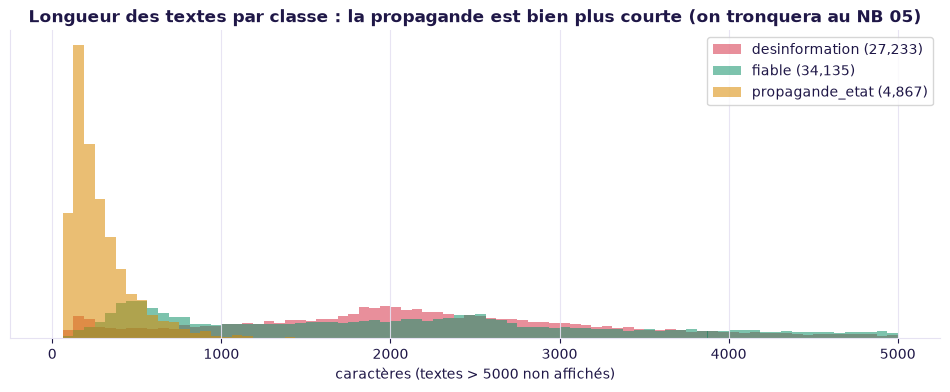

In [9]:
infowar = infowar[infowar["texte"].str.len() >= 100]
tracer("INFOWAR", "textes < 100 caractères écartés", len(infowar))

infowar["empreinte"] = infowar["texte"].map(empreinte)
labels_par_texte = infowar.groupby("empreinte")["label"].agg(frozenset)
print("Textes présents sous plusieurs étiquettes :")
display(labels_par_texte[labels_par_texte.map(len) > 1].map(lambda s: " + ".join(sorted(s))).value_counts())

# Vrai conflit : un même texte étiqueté à la fois « fiable » et autre chose → on ne peut pas trancher, on retire.
vrais_conflits = labels_par_texte[labels_par_texte.map(lambda s: "fiable" in s and len(s) > 1)].index
infowar = infowar[~infowar["empreinte"].isin(vrais_conflits)]
tracer("INFOWAR", "conflits vrai/faux retirés", len(infowar))

# Sinon, l'étiquette la plus précise gagne : propagande_etat > desinformation.
PRIORITE = {"propagande_etat": 0, "desinformation": 1, "fiable": 2}
infowar = infowar.sort_values("label", key=lambda s: s.map(PRIORITE)).drop_duplicates("empreinte")
tracer("INFOWAR", "doublons fusionnés", len(infowar))

infowar["longueur"] = infowar["texte"].str.len()
infowar[["texte", "label", "longueur"]].to_parquet(OUTPUTS / "entrainement_infowar.parquet", index=False)

fig, ax = plt.subplots(figsize=(12, 4))
COULEUR_LABEL = {"fiable": OK, "desinformation": ALERTE, "propagande_etat": VEILLE}
for label, grp in infowar.groupby("label"):
    ax.hist(grp["longueur"], bins=80, range=(0, 5000), density=True, alpha=0.55,
            label=f"{label} ({len(grp):,})", color=COULEUR_LABEL[label])
ax.set_title("Longueur des textes par classe : la propagande est bien plus courte (on tronquera au NB 05)")
ax.set_xlabel("caractères (textes > 5000 non affichés)")
ax.set_yticks([])
ax.legend()
plt.show()

> **Découverte en cours de route :** les 4 867 textes « propagande d'État » restants se retrouvent **tous** dans le jeu « faux ». Le sous-ensemble `EXTRA_RussianPropagandaSubset` a donc été **extrait** du jeu de désinformation. Avec une règle naïve (« doublon contradictoire, on supprime »), on aurait effacé **toute** la classe propagande sans s'en rendre compte. Un analyste lit ses données avant d'appliquer une règle.

## 5. Bonus : collecte en direct (flux RSS)

Le data lake est figé. Un vrai système de veille **tourne en continu**. Voici le collecteur : il interroge des flux RSS publics et produit des documents **au même format** que le corpus GOLFE. Tous les notebooks suivants peuvent donc les analyser sans modification.

> **Éthique OSINT :** on n'utilise que des flux publics prévus pour être lus par des machines (c'est le but du RSS). Le collecteur s'identifie poliment et on ne martèle pas les serveurs. Le renseignement d'origine sources ouvertes reste dans un cadre légal.

Mets `COLLECTE_LIVE = True` pour lancer la collecte (connexion internet requise, et `pip install feedparser`).

In [10]:
COLLECTE_LIVE = False

FLUX = {
    "BBC World": "https://feeds.bbci.co.uk/news/world/rss.xml",
    "BBC Middle East": "https://feeds.bbci.co.uk/news/world/middle_east/rss.xml",
    "Al Jazeera": "https://www.aljazeera.com/xml/rss/all.xml",
    "The Guardian World": "https://www.theguardian.com/world/rss",
    "DW": "https://rss.dw.com/rdf/rss-en-world",
    "France 24": "https://www.france24.com/en/rss",
    "ONU Info": "https://news.un.org/feed/subscribe/en/news/all/rss.xml",
    "Defense News": "https://www.defensenews.com/arc/outboundfeeds/rss/",
}


def collecter_rss(flux):
    import socket
    import feedparser

    socket.setdefaulttimeout(15)
    lignes = []
    for source, url in flux.items():
        d = feedparser.parse(url, agent="SpiritDigger/1.0 (projet etudiant OSINT)")
        for e in d.entries:
            quand = e.get("published_parsed") or e.get("updated_parsed")
            lignes.append({
                "date": pd.Timestamp(*quand[:6]) if quand else pd.NaT,
                "source": source, "camp": "RSS",
                "titre": nettoyer_texte(e.get("title", "")),
                "texte": nettoyer_texte(e.get("summary", "")),
                "langue": "en", "url": e.get("link", ""), "theatre": "LIVE",
            })
        print(f"  {source:<20} {len(d.entries):>3} articles")
    live = pd.DataFrame(lignes).drop_duplicates("url").reset_index(drop=True)
    horodatage = pd.Timestamp.now().strftime("%Y%m%d_%H%M")
    live["doc_id"] = [f"L-{horodatage}-{i:04d}" for i in range(len(live))]
    return live[COLONNES]


if COLLECTE_LIVE:
    live = collecter_rss(FLUX)
    chemin = OUTPUTS / f"collecte_live_{pd.Timestamp.now():%Y%m%d_%H%M}.parquet"
    live.to_parquet(chemin, index=False)
    print(f"\n{len(live)} articles collectés → {chemin.name}")
    display(live[["date", "source", "titre"]].head(10))
else:
    print("Collecte en direct désactivée (COLLECTE_LIVE = False).")

Collecte en direct désactivée (COLLECTE_LIVE = False).


## 6. Bilan du pipeline

In [11]:
bilan = pd.DataFrame(journal)
display(bilan)

produits = pd.DataFrame([
    {"produit": f.name, "documents": len(pd.read_parquet(f)), "taille_Mo": round(f.stat().st_size / 1e6, 1)}
    for f in sorted(OUTPUTS.glob("*.parquet"))
])
print(f"Data lake brut : ~790 Mo  →  produits propres : {produits.taille_Mo.sum():.0f} Mo")
produits

,corpus,étape,documents
0,GOLFE,chargement brut,2286
1,GOLFE,doublons d'URL retirés,2286
2,GOLFE,doublons de contenu retirés,2251
3,GOLFE,textes < 200 caractères écartés,2231
4,UKRAINE,chargement brut,386889
5,UKRAINE,messages < 30 caractères écartés,384257
6,UKRAINE,republications (même chaîne) retirées,382217
7,INFOWAR,chargement brut,85986
8,INFOWAR,textes < 100 caractères écartés,82294
9,INFOWAR,conflits vrai/faux retirés,82288


Data lake brut : ~790 Mo  →  produits propres : 262 Mo


,produit,documents,taille_Mo
0,cache_ner_golfe.parquet,85891,0.4
1,corpus_golfe.parquet,2231,4.0
2,corpus_ukraine.parquet,382217,137.8
3,entites_golfe.parquet,82456,0.7
4,entrainement_infowar.parquet,66235,118.9
5,verite_terrain_hormuz.parquet,125,0.0


## Ce qu'il faut retenir

- **Quatre corpus propres** au même schéma, prêts pour l'IA.
- **Le nettoyage est mesuré** : dans la classe désinformation, la part de textes portant une signature de source passe de 31 % à environ 0,2 %.
- **Une anomalie de provenance a été démasquée** : le jeu « propagande » est entièrement extrait du jeu « faux ».
- **Le dédoublonnage est intelligent** : on retire la répétition au sein d'une même chaîne, mais on garde la même information portée par plusieurs camps, car c'est la matière première du recoupement.
- **Le collecteur live** permet de brancher Spirit Digger sur l'actualité du jour.

> **Phrase de démo :** « Spirit Digger ingère près de 800 Mo de sources hétérogènes en trois langues. Il neutralise les marqueurs qui trahissent l'origine d'un texte et livre des corpus normalisés. Il peut aussi se brancher en direct sur huit flux internationaux. »

**Prochaine étape → NB 02 : Scan et inventaire (extraction d'entités).**